# 04-1. 결빙 분류: 후보 모델과 교차검증

10분 단위로 결빙 여부를 예측하고 검증 지점에서 평가한다(04).
이 노트북은 0~1장으로, Ice 라벨의 특성을 보고 후보 모델을 지점 단위 교차검증으로 비교해 최종 모델과 임계값을 정한다.

04 구성: **04-1 Ice 라벨·후보 모델·교차검증(0~1장)** · 04-2 고전 ML 비교(2장) · 04-3 검증 지점 평가·저장(3~5장)

- 노면상태 Ice → 결빙, 그 외 → 비결빙
- 일별(00:00~23:50) TP·FP·FN으로 F1-score, Precision, Recall 계산 후 평가기간 평균
- 지점별 평균과 세 지점 평균을 함께 제시 (QnA 2026-09-29)

검증 지점은 미관측 지점으로 보고, **그 지점의 실측값(노면온도·노면상태)은 입력으로 쓰지 않는다.**
03-3에서 추정한 노면온도와 02-2의 보간 기상·주변 RWIS 변수만 쓴다.

- 입력: 02-2의 지점 변수, 03-3의 추정 노면온도 (`data/processed/`)
- 출력: 최종 결빙 분류 모델(`model/icing_*`), 교차검증 확률·설정·후보 모델(`data/processed/icing_*`, 04-2·04-3에서 사용), 교차검증 성능·변수 중요도(`data/results/`)

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parents[1]  # notebooks/<단계 폴더>/ 에서 실행
sys.path.insert(0, str(ROOT))

from src import config

In [2]:
import json
import time
import warnings

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib import font_manager
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

for font in ["NanumGothic", "Malgun Gothic", "AppleGothic"]:
    if any(f.name == font for f in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = font
        break
plt.rcParams.update({
    "axes.unicode_minus": False,
    "axes.prop_cycle": cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                     "#e87ba4", "#008300", "#4a3aa7", "#e34948"]),
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "figure.dpi": 100, "lines.linewidth": 1.5,
})
SEED = 42

In [3]:
sf = pd.read_parquet(config.PROCESSED_DIR / "station_features.parquet")
sf = sf.merge(pd.read_parquet(config.PROCESSED_DIR / "station_estimates.parquet"), on=["stn", "time"])
stations = pd.read_parquet(config.PROCESSED_DIR / "stations.parquet").set_index("stn")
meta = json.load(open(config.PROCESSED_DIR / "features.json", encoding="utf-8"))

sf["rst_dpd"] = sf["rst_est"] - sf["td"]  # 추정 노면온도 - 이슬점: 음수면 노면에 서리·응결이 생길 수 있다
sf["date"] = sf["time"].dt.normalize()
print(sf.shape, "Ice:", int(sf["ice"].sum()), "라벨 없음:", int(sf["ice"].isna().sum()))

(587520, 50) Ice: 303 라벨 없음: 4162


## 0. Ice 라벨의 특성

모델을 만들기 전에 Ice가 시간적으로 어떻게 나타나는지 본다.

In [4]:
runs, around = [], []
for stn, g in sf.sort_values(["stn", "time"]).groupby("stn"):
    x = (g["ice"] == 1).to_numpy().astype(int)
    edge = np.diff(np.r_[0, x, 0])
    runs += list(np.flatnonzero(edge == -1) - np.flatnonzero(edge == 1))
    states = g["state"].to_numpy()
    for i in np.flatnonzero(x):
        around += [s for s in states[max(i - 3, 0):i + 4] if s != 4 and not np.isnan(s)]
print("Ice 연속 길이(10분 단위) 분포:", pd.Series(runs).value_counts().sort_index().to_dict())
STATE_NAMES = {1: "Dry", 2: "Wet", 3: "Snow", 4: "Ice", 10: "저시정", 11: "물고임", 12: "Damp+저온(제빙)",
               13: "결빙시작(제빙)", 14: "Damp", 15: "판별불가"}
print("Ice 앞뒤 30분의 다른 노면상태:")
print(pd.Series(around).map(STATE_NAMES).value_counts().to_string())

Ice 연속 길이(10분 단위) 분포: {1: 248, 2: 18, 3: 5, 4: 1}
Ice 앞뒤 30분의 다른 노면상태:
Damp+저온(제빙)    574
판별불가           406
Dry            234
Wet            202
Snow           164
Damp            70
결빙시작(제빙)        34


- Ice는 대부분 **10분 한 번만 나타나고 바로 다른 상태로 바뀐다** (연속 1회가 90% 이상).
- 앞뒤로는 Damp+저온(12), 판별불가(15), Snow(3)가 많다. 실제로는 수십 분~수 시간 이어지는 "젖은 노면이 어는 상황" 안에서
  센서 판정이 Ice와 비슷한 상태 사이를 오가는 것으로 보인다.

이런 라벨을 10분 단위로 맞히는 것이 얼마나 어려운지 보려고, **그 지점의 실제 노면상태를 안다고 가정한 상한**을 계산한다.

In [5]:
def daily_icing_scores(df, empty_day="skip"):
    """한 지점(또는 여러 지점)의 일별 TP, FP, FN, Precision, Recall, F1.

    Args:
        df: stn, time, y_true(0/1), y_pred(0/1) 컬럼을 가진 10분 단위 DataFrame. y_true가 NaN인 시각은 뺀다.
        empty_day: 실제·예측 모두 결빙이 없는 날(TP+FP+FN=0)의 처리
            "skip" - 평균에서 뺀다 (기본)
            "one"  - 완벽히 맞힌 날로 보고 1점을 준다
    분모가 0인 지표(예: 예측이 없는 날의 Precision)는 0으로 둔다.
    """
    d = df.dropna(subset=["y_true"]).copy()
    d["date"] = d["time"].dt.normalize()
    y, p = d["y_true"].astype(int), d["y_pred"].astype(int)
    d["TP"], d["FP"], d["FN"] = y & p, (1 - y) & p, y & (1 - p)
    day = d.groupby(["stn", "date"])[["TP", "FP", "FN"]].sum()
    tp, fp, fn = day["TP"], day["FP"], day["FN"]
    day["Precision"] = np.where(tp + fp > 0, tp / (tp + fp).replace(0, 1), 0.0)
    day["Recall"] = np.where(tp + fn > 0, tp / (tp + fn).replace(0, 1), 0.0)
    day["F1"] = np.where(2 * tp + fp + fn > 0, 2 * tp / (2 * tp + fp + fn).replace(0, 1), 0.0)
    empty = (tp + fp + fn) == 0
    day.loc[empty, ["Precision", "Recall", "F1"]] = np.nan if empty_day == "skip" else 1.0
    day["evaluated"] = ~empty if empty_day == "skip" else True
    return day.reset_index()


def daily_f1(df, pred, empty_day="skip"):
    """여러 지점의 일별 F1을 지점별로 평균한 뒤 다시 지점 평균한 값 (모델 선택용 한 숫자)."""
    day = daily_icing_scores(pd.DataFrame({"stn": df["stn"].values, "time": df["time"].values,
                                           "y_true": df["ice"].values, "y_pred": np.asarray(pred, int)}), empty_day)
    return day.groupby("stn")["F1"].mean().mean()


oracle = {
    "Ice (정답 그대로)": sf["state"] == 4,
    "Snow·Ice·결빙시작·판별불가": sf["state"].isin([3, 4, 13, 15]),
    "실측 노면온도 ≤ 0°C & 젖은 노면": (sf["rst"] <= 0) & sf["state"].isin([2, 3, 4, 11, 12, 13, 14, 15]),
}
pd.Series({k: daily_f1(sf, v) for k, v in oracle.items()}, name="일별 F1 지점 평균 (17개소)").round(3).to_frame()

,일별 F1 지점 평균 (17개소)
Ice (정답 그대로),1.000
Snow·Ice·결빙시작·판별불가,0.072
실측 노면온도 ≤ 0°C & 젖은 노면,0.010


그 지점의 실제 노면상태를 알아도 "결빙 관련 상태 전체"를 결빙으로 예측하면 일별 F1이 0.1에도 못 미친다.
실측 노면온도와 젖음 여부로 판단해도 0.01 수준이다. **이 평가 방식에서 10분 단위 Ice를 맞히는 것은 본질적으로 매우 어렵고,
미관측 지점에서의 기대 성능도 낮을 수밖에 없다.** 이를 전제로 모델을 만든다.

## 1. 모델 구성 및 학습

### 입력 변수
추정 노면온도(03)와 노면-이슬점 차, 보간 기상, 주변 RWIS 노면상태, 시간·일사.
03과 같은 이유로(학습 지점 14곳의 고유 특성을 외우는 문제) 정적 변수는 넣지 않는다.

### 후보

| 이름 | 방법 |
|------|------|
| 규칙 기반 | 추정 노면온도 ≤ 0°C, 습도 ≥ 80%, 주변 RWIS 젖은 노면 비율 ≥ 0.5 이면 결빙 (학습 없음) |
| Bonanno 결빙 기준 | 노면에 수분(강수·최근 12시간 강수·적설·노면 ≤ 이슬점)이 있을 때, 강수 중이면 추정 노면온도 < 1°C, 아니면 < 0°C (Bonanno et al. 2010, Hong et al. 2022에서 재인용, 학습 없음) |
| 서리 조건(Jang) | 추정 노면온도 ≤ 0°C 이고 추정 노면온도 ≤ 보간 이슬점 (Jang 2024, 학습 없음) |
| LightGBM(Ice 라벨) | Ice(1)/그 외(0)를 직접 학습 |
| LightGBM(결빙관련 라벨) | Snow·Ice·결빙시작·판별불가(1)를 학습. 양성 사례가 약 20배 많아 "결빙 상황"을 더 안정적으로 배운다 |
| 로지스틱 회귀(결빙관련 라벨) | 같은 라벨·변수의 선형 모델 (표준화, L2 규제 C=0.1). 계수로 변수의 영향 방향과 크기를 직접 읽을 수 있다 |

학습 모델 후보는 지점 단위 교차검증(03과 같은 7묶음)으로 학습 지점의 예측 확률(out-of-fold)을 만들고,
그 확률에서 **일별 F1 지점 평균이 가장 높은 임계값**을 고른다. 최종 모델을 고른 과정은 교차검증 결과 아래에 따로 적는다.
양성(결빙) 가중치는 Ice 라벨 20, 결빙관련 라벨 5로 둔다 (양성 비율 차이 반영).

In [6]:
CLS_FEATURES = ["rst_est", "rst_dpd", "ta", "td", "rh", "rh_mean3h", "ws", "rain", "pr60", "pr12h", "rain_hrs12h",
                "hrs_since_rain", "snow", "cloud", "ta_min12h", "ta_d3h", "nbr_ice", "nbr_ice_3h", "nbr_wet",
                "nbr_snow", "nbr_rst", "hour_sin", "hour_cos", "sun_elev", "sunlit", "season_day"]
RELATED_STATES = [3, 4, 13, 15]
sf["related"] = sf["state"].isin(RELATED_STATES).astype("float32").where(sf["state"].notna())

train_all = sf[~sf["stn"].isin(config.HOLDOUT_STATIONS)].reset_index(drop=True)
holdout = sf[sf["stn"].isin(config.HOLDOUT_STATIONS)].reset_index(drop=True)
stns = sorted(train_all["stn"].unique())
folds = [stns[i::7] for i in range(7)]
print("학습 지점 Ice:", int(train_all["ice"].sum()), "/ 결빙관련:", int(train_all["related"].sum()))

PARAMS = dict(objective="binary", learning_rate=0.03, n_estimators=400, num_leaves=15, min_child_samples=200,
              subsample=0.7, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
              random_state=SEED, n_jobs=-1, verbose=-1)
LOGIT_C = 0.1
CANDIDATES = {
    "LightGBM(Ice 라벨)": {"kind": "lightgbm", "label": "ice", "pos_weight": 20},
    "LightGBM(결빙관련 라벨)": {"kind": "lightgbm", "label": "related", "pos_weight": 5},
    "로지스틱 회귀(결빙관련 라벨)": {"kind": "logistic", "label": "related", "pos_weight": 5},
}


def make_classifier(kind, pos_weight):
    """kind: "lightgbm" 또는 "logistic". 로지스틱은 결측을 중앙값으로 채우고 표준화한다."""
    if kind == "lightgbm":
        return lgb.LGBMClassifier(**PARAMS, scale_pos_weight=pos_weight)
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                         LogisticRegression(C=LOGIT_C, class_weight={0: 1, 1: pos_weight}, max_iter=2000))


def train_icing_classifier(train_df, cfg, features=CLS_FEATURES):
    """10분 단위 결빙(1)/비결빙(0) 분류 모델을 학습한다. cfg: CANDIDATES의 설정."""
    d = train_df.dropna(subset=[cfg["label"]])
    return make_classifier(cfg["kind"], cfg["pos_weight"]).fit(d[features], d[cfg["label"]].astype(int))


def predict_icing(model, df, features=CLS_FEATURES):
    """10분 단위 결빙 확률."""
    return model.predict_proba(df[features])[:, 1]


oof_prob = pd.DataFrame(index=train_all.index)
t0 = time.time()
for name, c in CANDIDATES.items():
    prob = pd.Series(np.nan, index=train_all.index)
    for val_stns in folds:
        m = train_icing_classifier(train_all[~train_all["stn"].isin(val_stns)], c)
        rows = train_all["stn"].isin(val_stns)
        prob[rows] = predict_icing(m, train_all[rows])
    oof_prob[name] = prob
    print(f"{name}: 교차검증 완료 ({time.time() - t0:.0f}s)")

학습 지점 Ice: 239 / 결빙관련: 5715


LightGBM(Ice 라벨): 교차검증 완료 (57s)


LightGBM(결빙관련 라벨): 교차검증 완료 (95s)


로지스틱 회귀(결빙관련 라벨): 교차검증 완료 (111s)


In [7]:
def rule_based(df):
    return ((df["rst_est"] <= 0) & (df["rh"] >= 80) & (df["nbr_wet"] >= 0.5)).to_numpy()


def bonanno_rule(df):
    """Bonanno et al.(2010): 노면에 수분이 있을 때 강수 중이면 노면 < 1°C, 강수가 없으면 노면 < 0°C에서 결빙."""
    raining = df["rain"] >= 0.5
    moist = raining | (df["rain_hrs12h"] > 0) | (df["snow"] > 0) | (df["rst_dpd"] <= 0)
    return (moist & np.where(raining, df["rst_est"] < 1, df["rst_est"] < 0)).to_numpy()


def frost_rule(df):
    """Jang(2024)의 서리 조건: 노면온도 ≤ 0°C 이고 노면온도 ≤ 이슬점."""
    return ((df["rst_est"] <= 0) & (df["rst_dpd"] <= 0)).to_numpy()


RULES = {"규칙 기반": rule_based, "Bonanno 결빙 기준": bonanno_rule, "서리 조건(Jang)": frost_rule}


def best_threshold(df, prob, quantiles=(0.95, 0.98, 0.99, 0.995, 0.998, 0.999, 0.9995, 0.9998)):
    """교차검증 확률에서 일별 F1 지점 평균이 가장 높은 임계값."""
    cands = np.unique(np.quantile(prob[~np.isnan(prob)], quantiles))
    scores = {float(t): daily_f1(df, prob >= t) for t in cands}
    return max(scores, key=scores.get), scores


labeled = train_all["ice"].notna()
no_pred = np.zeros(len(train_all), dtype=int)
rows = [{"방법": "예측 없음(참고)", "임계값": np.nan, "AP(Ice)": np.nan,
         "일별 F1 (빈 날 제외)": daily_f1(train_all, no_pred), "일별 F1 (빈 날 1점)": daily_f1(train_all, no_pred, "one")}]
for name, rule in RULES.items():
    pred = rule(train_all)
    rows.append({"방법": name, "임계값": np.nan, "AP(Ice)": np.nan,
                 "일별 F1 (빈 날 제외)": daily_f1(train_all, pred), "일별 F1 (빈 날 1점)": daily_f1(train_all, pred, "one"),
                 "Ice 포착률(10분)": pred[labeled & (train_all["ice"] == 1)].mean(), "결빙 판정 비율": pred.mean()})
thresholds = {}
for name in CANDIDATES:
    prob = oof_prob[name].to_numpy()
    thr, _ = best_threshold(train_all, prob)
    thresholds[name] = thr
    rows.append({"방법": name, "임계값": thr,
                 "AP(Ice)": average_precision_score(train_all.loc[labeled, "ice"], prob[labeled]),
                 "일별 F1 (빈 날 제외)": daily_f1(train_all, prob >= thr),
                 "일별 F1 (빈 날 1점)": daily_f1(train_all, prob >= thr, "one"),
                 "Ice 포착률(10분)": (prob >= thr)[labeled & (train_all["ice"] == 1)].mean(),
                 "결빙 판정 비율": (prob >= thr).mean()})
cv_table = pd.DataFrame(rows).set_index("방법")
print("참고: Ice 비율(무작위 예측의 AP) =", round(train_all.loc[labeled, "ice"].mean(), 5))
cv_table.round(4)

참고: Ice 비율(무작위 예측의 AP) = 0.0005


,임계값,AP(Ice),일별 F1 (빈 날 제외),일별 F1 (빈 날 1점),Ice 포착률(10분),결빙 판정 비율
방법,,,,,,
예측 없음(참고),NaN,NaN,0.0000,0.9667,NaN,NaN
규칙 기반,NaN,NaN,0.0066,0.6926,0.4728,0.0641
Bonanno 결빙 기준,NaN,NaN,0.0047,0.6402,0.6987,0.1400
서리 조건(Jang),NaN,NaN,0.0004,0.9440,0.0042,0.0017
LightGBM(Ice 라벨),0.2135,0.0053,0.0126,0.9320,0.0335,0.0010
LightGBM(결빙관련 라벨),0.8481,0.0098,0.0256,0.9312,0.1506,0.0050
로지스틱 회귀(결빙관련 라벨),0.7035,0.0089,0.0288,0.9141,0.2385,0.0100


In [8]:
cv_best = cv_table.loc[list(CANDIDATES), "일별 F1 (빈 날 제외)"].idxmax()
FINAL = "LightGBM(결빙관련 라벨)"       # 선택 근거는 아래 설명 참고
INTERPRET = "로지스틱 회귀(결빙관련 라벨)"  # 해석용으로 함께 제시하는 모델
THRESHOLD = thresholds[FINAL]
print(f"교차검증 일별 F1 1위: {cv_best}")
print(f"최종 모델: {FINAL} (임계값 {THRESHOLD:.3f}), 해석용 모델: {INTERPRET}")

교차검증 일별 F1 1위: 로지스틱 회귀(결빙관련 라벨)
최종 모델: LightGBM(결빙관련 라벨) (임계값 0.848), 해석용 모델: 로지스틱 회귀(결빙관련 라벨)


- **빈 날 1점** 방식은 결빙이 없는 날이 대부분이라, 아무것도 예측하지 않아도(예측 없음) 가장 높은 점수가 나온다. 모델 비교에는 쓸모가 없으므로
  모델 선택과 임계값은 **빈 날 제외** 방식으로 정했다. 두 방식 모두 제출 표에 함께 제시한다.
- 결빙관련 라벨로 학습한 모델이 Ice만 학습한 모델보다 AP·일별 F1이 모두 높다.
- 교차검증 일별 F1은 로지스틱 회귀가 가장 높다 (0.029, LightGBM 결빙관련 0.026). 하지만 이 차이는 2절의 부트스트랩 95% 구간 안이라
  우연과 구분되지 않는다. AP도 Ice 기준으로는 LightGBM(0.0098 vs 0.0089), 결빙관련 기준으로는 로지스틱(0.486 vs 0.470)이 높아 엇갈린다.
- **최종 모델은 LightGBM(결빙관련 라벨)으로 한다.** 교차검증으로 우열이 갈리지 않아서, Ice 자체를 가려내는 순위 성능(AP(Ice))과
  검증 지점 결과(3·4절: 일별 F1 0.010 vs 0.006, 오탐일 12일 vs 19일)를 함께 보고 정했다.
  로지스틱은 고른 임계값에서 전체 시간의 1.0%를 결빙으로 판정해 LightGBM(0.5%)의 두 배이고, 그만큼 오탐이 많다.
  **검증 지점 결과를 모델 선택에 참고했으므로 4절의 검증 지점 성능은 조금 낙관적일 수 있다.**
- **로지스틱 회귀는 해석용 모델로 함께 제시한다.** 성능이 LightGBM과 같은 수준이면서, 계수로 각 요인이 결빙 쪽인지 아닌지와
  그 크기를 바로 읽을 수 있기 때문이다 (아래 '최종 모델 해석').
- **이론 기준만으로 판정하면 성능이 낮다.** Bonanno 결빙 기준은 Ice 10분의 70%를 포함하지만 전체 시간의 14%를 결빙으로 판정해
  오탐한 날이 많다. 결빙이 "가능한" 조건(필요조건)이지 센서가 Ice로 판정하는 조건이 아니기 때문이다.
  서리 조건은 Ice를 거의 포함하지 않는다 (01-6의 13-3: 서리 조건의 0.35%만 Ice).

### 최종 모델 해석

학습 지점 14곳 전체로 최종 모델(LightGBM)과 해석용 로지스틱 회귀를 학습한다. LightGBM의 변수 중요도(gain)와
로지스틱 회귀의 **표준화 계수**(변수 1 표준편차 증가 시 로그 오즈 변화)를 함께 본다. 서로 상관이 큰 변수(추정 노면온도·노면-이슬점 차·주변 노면온도, 기온·이슬점 등)는
계수를 나눠 가지므로 개별 계수보다 **변수군** 단위로 읽는다. 변수군의 중요도는 변수군 전체를 함께 섞었을 때(permutation)
결빙관련 AP가 얼마나 떨어지는지로 잰다. 두 모델에 같은 기준을 쓸 수 있다.

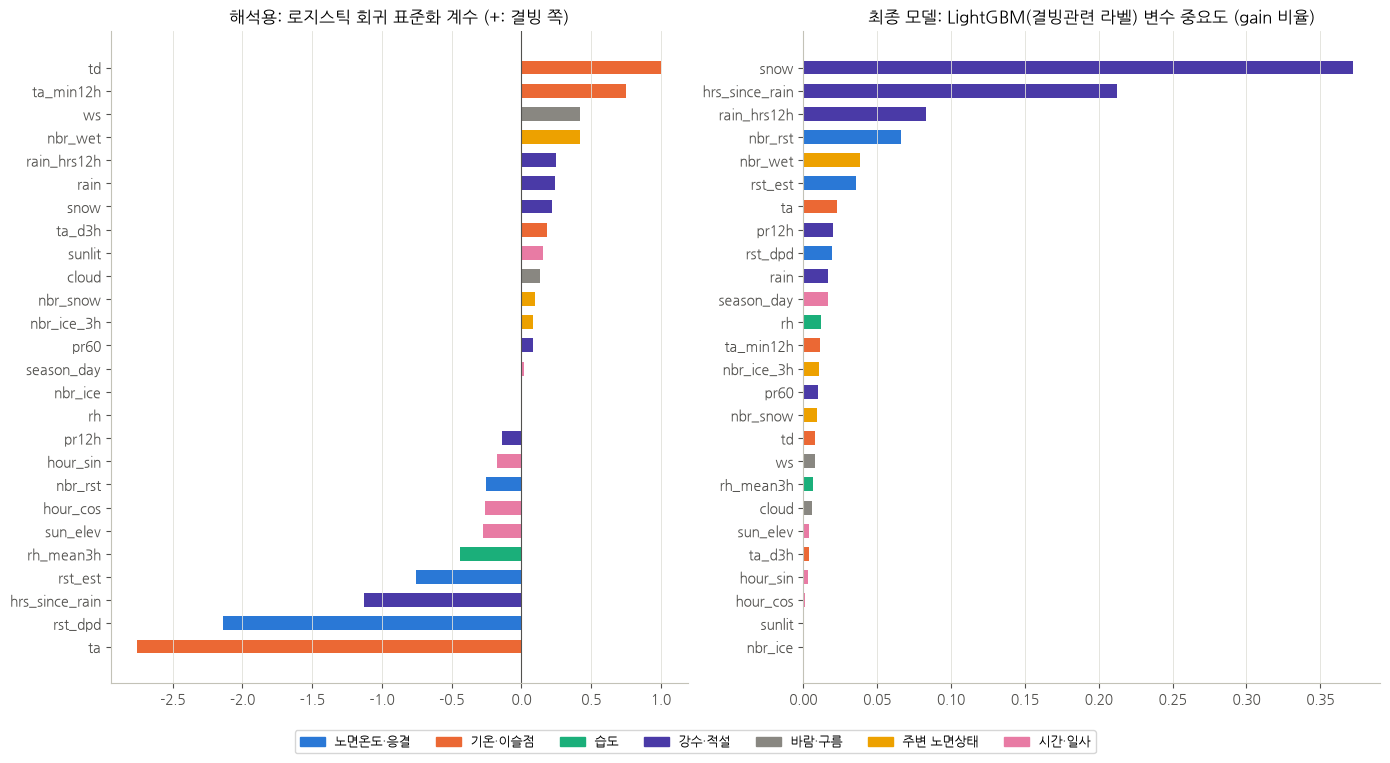

변수군을 섞었을 때 결빙관련 AP 감소 (학습 지점, 15만 행 표본)


,로지스틱 회귀,LightGBM
강수·적설,0.370,0.614
노면온도·응결,0.222,0.296
기온·이슬점,0.167,0.252
주변 노면상태,0.078,0.086
바람·구름,0.026,0.035
습도,0.020,0.048
시간·일사,0.004,0.069


In [9]:
final_cfg = CANDIDATES[FINAL]
full_models = {name: train_icing_classifier(train_all, CANDIDATES[name])
               for name in dict.fromkeys([FINAL, INTERPRET, "LightGBM(결빙관련 라벨)"])}
model = full_models[FINAL]
logit_model, lgb_model = full_models[INTERPRET], full_models["LightGBM(결빙관련 라벨)"]

FEATURE_GROUPS = {
    "노면온도·응결": ["rst_est", "rst_dpd", "nbr_rst"],
    "기온·이슬점": ["ta", "td", "ta_min12h", "ta_d3h"],
    "습도": ["rh", "rh_mean3h"],
    "강수·적설": ["rain", "pr60", "pr12h", "rain_hrs12h", "hrs_since_rain", "snow"],
    "바람·구름": ["ws", "cloud"],
    "주변 노면상태": ["nbr_ice", "nbr_ice_3h", "nbr_wet", "nbr_snow"],
    "시간·일사": ["hour_sin", "hour_cos", "sun_elev", "sunlit", "season_day"],
}
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
GROUP_COLORS = dict(zip(FEATURE_GROUPS, ["#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#898781", "#eda100", "#e87ba4"]))

coef = pd.Series(logit_model[-1].coef_[0], index=CLS_FEATURES).sort_values()
gain = pd.Series(lgb_model.booster_.feature_importance("gain"), index=CLS_FEATURES)
gain = (gain / gain.sum()).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 7.5))
axes[0].barh(coef.index, coef.values, height=0.6, color=[GROUP_COLORS[group_of[f]] for f in coef.index])
axes[0].axvline(0, color="#52514e", linewidth=0.8)
axes[0].set_title("해석용: 로지스틱 회귀 표준화 계수 (+: 결빙 쪽)")
axes[1].barh(gain.index, gain.values, height=0.6, color=[GROUP_COLORS[group_of[f]] for f in gain.index])
axes[1].set_title("최종 모델: LightGBM(결빙관련 라벨) 변수 중요도 (gain 비율)")
for ax in axes:
    ax.grid(axis="y", visible=False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COLORS.values()]
fig.legend(handles, GROUP_COLORS, ncol=7, loc="lower center", bbox_to_anchor=(0.5, -0.02), fontsize=9)
plt.tight_layout(rect=(0, 0.03, 1, 1))
plt.show()


def group_permutation_drop(m, df, label="related", n_repeat=3):
    """변수군을 함께 섞었을 때 AP(결빙관련)가 떨어지는 양."""
    d = df.dropna(subset=[label])
    sample = d.sample(min(len(d), 150_000), random_state=SEED)
    y = sample[label].astype(int)
    base = average_precision_score(y, predict_icing(m, sample))
    rng = np.random.default_rng(SEED)
    out = {}
    for g, cols in FEATURE_GROUPS.items():
        drops = []
        for _ in range(n_repeat):
            shuffled = sample.copy()
            perm = rng.permutation(len(sample))
            shuffled[cols] = sample[cols].to_numpy()[perm]
            drops.append(base - average_precision_score(y, predict_icing(m, shuffled)))
        out[g] = np.mean(drops)
    return pd.Series(out)


group_imp = pd.DataFrame({"로지스틱 회귀": group_permutation_drop(logit_model, train_all),
                          "LightGBM": group_permutation_drop(lgb_model, train_all)})
coef_table = pd.DataFrame({"변수군": [group_of[f] for f in CLS_FEATURES],
                           "표준화 계수": coef.reindex(CLS_FEATURES).values,
                           "1SD당 오즈비": np.exp(coef.reindex(CLS_FEATURES).values),
                           "LightGBM gain 비율": gain.reindex(CLS_FEATURES).values}, index=CLS_FEATURES)
print("변수군을 섞었을 때 결빙관련 AP 감소 (학습 지점, 15만 행 표본)")
group_imp.sort_values("로지스틱 회귀", ascending=False).round(3)

In [10]:
coef_table.sort_values("표준화 계수").round(3)

,변수군,표준화 계수,1SD당 오즈비,LightGBM gain 비율
ta,기온·이슬점,-2.757,0.063,0.023
rst_dpd,노면온도·응결,-2.139,0.118,0.019
hrs_since_rain,강수·적설,-1.129,0.323,0.213
rst_est,노면온도·응결,-0.755,0.470,0.036
rh_mean3h,습도,-0.441,0.643,0.006
sun_elev,시간·일사,-0.278,0.757,0.004
hour_cos,시간·일사,-0.259,0.771,0.002
nbr_rst,노면온도·응결,-0.257,0.773,0.066
hour_sin,시간·일사,-0.178,0.837,0.003
pr12h,강수·적설,-0.139,0.871,0.020


- 두 모델 모두 **강수·적설 > 노면온도·응결 > 기온·이슬점 > 주변 노면상태** 순으로 변수군에 의존한다.
  변수군을 섞었을 때 결빙관련 AP 감소는 로지스틱 0.37 / 0.22 / 0.17 / 0.08, LightGBM 0.61 / 0.30 / 0.25 / 0.09이다.
  습도·바람·구름·시간은 작다. 결빙은 저온과 수분 공급이 함께 있을 때 생긴다는 01-6의 13장 결론(Ice의 81%가 강수 중·직후)과 같은 구조이다.
- 로지스틱 계수의 방향도 물리적으로 해석된다 (괄호는 표준화 계수).
  - **차가울수록 결빙 쪽**: 기온(-2.76), 노면-이슬점 차(-2.14, 노면이 이슬점보다 낮을수록 응결·서리), 추정 노면온도(-0.75)
  - **비가 그친 지 오래될수록 비결빙 쪽**: 강수 후 경과 시간(-1.13, 1 표준편차당 오즈 0.32배). 노면이 마르기 때문이다.
  - **수분 공급은 결빙 쪽**: 이슬점(+1.00, 같은 기온에서 공기가 습할수록), 주변 RWIS의 젖은 노면 비율(+0.42), 강수(+0.24),
    최근 12시간 강수 시간(+0.25), 적설(+0.22)
  - 풍속(+0.42)은 바람이 강한 강설·한파 상황을 반영하는 것으로 보인다.
- 12시간 최저기온(+0.75)처럼 직관과 반대인 부호도 있다. 이는 현재 기온과 함께 들어간 상관 변수의 보정 효과이다.
  현재 기온이 같을 때 최근 최저기온이 높았다는 것은 지금 식고 있다는 뜻이다. 서로 상관이 큰 변수는 개별 계수보다 변수군 단위로 읽는다.

### 이론 기반 변수 추가 실험

01-6·01-7의 13장에서 확인한 이론 기반 변수 5개를 더하면 나아지는지 같은 교차검증으로 확인한다. 모두 추정 노면온도와 보간 기상으로 만들 수 있다.

| 변수 | 의미 | 근거 |
|------|------|------|
| `rst_max24h` | 직전 24시간 최고 추정 노면온도 (영상이었으면 녹은 물이 있을 수 있음) | 융해·재결빙 (01-6의 13-2) |
| `freeze_thaw24h` | 직전 24시간 동안 추정 노면온도가 0°C를 넘나든 횟수 | 동결-융해 (13-4) |
| `rst_d1h` | 1시간 노면온도 변화 (냉각 속도) | 13-4 |
| `stability` | Pasquill–Gifford 안정도 (0=D ~ 3=G) | Chapman et al. 2001 (13-5) |
| `bonanno` | Bonanno 결빙 기준 충족 여부 | 13-1 |

In [11]:
THEORY_FEATURES = ["rst_max24h", "freeze_thaw24h", "rst_d1h", "stability", "bonanno"]


def add_theory_features(df):
    """추정 노면온도·보간 기상으로 이론 기반 변수를 만든다 (지점별 시간 순서 기준)."""
    d = df.sort_values(["stn", "time"])
    g = d.groupby("stn")["rst_est"]
    above = (d["rst_est"] > 0).astype(float).where(d["rst_est"].notna())
    ws, octa = d["ws"], d["cloud"] * 0.8
    out = pd.DataFrame({
        "rst_max24h": g.transform(lambda s: s.rolling(144, min_periods=1).max()),
        "freeze_thaw24h": above.groupby(d["stn"]).transform(lambda s: s.diff().abs().rolling(144, min_periods=1).sum()),
        "rst_d1h": g.diff(6),
        "stability": np.select([ws > 5, (ws >= 3) & (octa >= 4), ws >= 3, (ws >= 2) & (octa >= 4), ws >= 2],
                               [0, 0, 1, 1, 2], 3).astype(float),
        "bonanno": bonanno_rule(d).astype(float),
    }, index=d.index)
    return out.reindex(df.index)


theory_train = train_all.join(add_theory_features(train_all))
feats_plus = CLS_FEATURES + THEORY_FEATURES
prob_plus = np.full(len(theory_train), np.nan)
t0 = time.time()
for val_stns in folds:
    m = train_icing_classifier(theory_train[~theory_train["stn"].isin(val_stns)], final_cfg, feats_plus)
    rows_val = theory_train["stn"].isin(val_stns).to_numpy()
    prob_plus[rows_val] = predict_icing(m, theory_train[rows_val], feats_plus)
thr_plus, _ = best_threshold(train_all, prob_plus)
print(f"교차검증 완료 ({time.time() - t0:.0f}s)")
pd.DataFrame({
    "AP(Ice)": [cv_table.loc[FINAL, "AP(Ice)"], average_precision_score(train_all.loc[labeled, "ice"], prob_plus[labeled])],
    "일별 F1 (빈 날 제외)": [cv_table.loc[FINAL, "일별 F1 (빈 날 제외)"], daily_f1(train_all, prob_plus >= thr_plus)],
}, index=[f"{FINAL}", f"{FINAL} + 이론 변수 5개"]).round(4)

교차검증 완료 (31s)


,AP(Ice),일별 F1 (빈 날 제외)
LightGBM(결빙관련 라벨),0.0098,0.0256
LightGBM(결빙관련 라벨) + 이론 변수 5개,0.0098,0.0226


이론 변수를 더해도 AP는 같고(0.0098 → 0.0098) 일별 F1은 오히려 낮다(0.026 → 0.023).
추정 노면온도·강수 이력·적설·운량·풍속이 이미 들어 있어서, 같은 정보를 다른 형태로 한 번 더 넣은 셈이기 때문으로 보인다.
**변수를 늘리지 않고 기존 변수를 유지한다** (검토한 대안).

## 저장

- `model/icing_lgbm.txt`, `model/icing_meta.json`: 최종 결빙 분류 모델과 변수·임계값 (05에서 사용)
- `data/processed/icing_models.joblib`: 학습 지점 14곳 전체로 학습한 후보 모델 3개 → 04-3의 검증 지점 예측
- `data/processed/icing_oof.parquet`: 학습 지점 교차검증 확률 → 04-2의 기법 비교
- `data/processed/icing_cv.json`: 변수, 결빙관련 상태, 교차검증 묶음, 후보 설정, 임계값, 최종·해석용 모델
- `data/results/icing_cv_scores.csv`, `icing_feature_importance.csv`: 교차검증 성능, 변수 중요도

In [12]:
if final_cfg["kind"] == "lightgbm":
    model_file, params = "icing_lgbm.txt", PARAMS
    model.booster_.save_model(config.MODEL_DIR / model_file)
else:
    model_file, params = "icing_logistic.joblib", {"C": LOGIT_C, "class_weight": {"0": 1, "1": final_cfg["pos_weight"]}}
    joblib.dump(model, config.MODEL_DIR / model_file)
with open(config.MODEL_DIR / "icing_meta.json", "w", encoding="utf-8") as f:
    json.dump({"method": FINAL, "model_type": final_cfg["kind"], "model_file": model_file,
               "label": final_cfg["label"], "label_states": RELATED_STATES, "features": CLS_FEATURES,
               "threshold": THRESHOLD, "params": params, "pos_weight": final_cfg["pos_weight"],
               "selection": "지점 단위 교차검증 일별 F1(빈 날 제외)"}, f, ensure_ascii=False, indent=2)

In [13]:
# 검증 지점 예측(04-3)에 쓸 후보 모델: 학습 지점 14곳 전체로 학습
for name, cfg in CANDIDATES.items():
    if name not in full_models:
        full_models[name] = train_icing_classifier(train_all, cfg)
joblib.dump(full_models, config.PROCESSED_DIR / "icing_models.joblib")
oof_prob.assign(stn=train_all["stn"], time=train_all["time"]).to_parquet(
    config.PROCESSED_DIR / "icing_oof.parquet", index=False)
cv_info = {"features": CLS_FEATURES, "related_states": RELATED_STATES, "folds": [[int(s) for s in v] for v in folds],
           "candidates": CANDIDATES, "thresholds": thresholds, "final": FINAL, "interpret": INTERPRET}
with open(config.PROCESSED_DIR / "icing_cv.json", "w", encoding="utf-8") as f:
    json.dump(cv_info, f, ensure_ascii=False, indent=2)

cv_table.round(4).to_csv(config.RESULT_DIR / "icing_cv_scores.csv", encoding="utf-8-sig")
coef_table.join(group_imp.add_prefix("변수군 AP 감소: "), on="변수군").round(4).to_csv(
    config.RESULT_DIR / "icing_feature_importance.csv", encoding="utf-8-sig")
print("저장 완료")

저장 완료
